# Practical 8: End-to-End Communication System Simulation over an ARINC 429 Link

**Communication Theory, Uganda Christian University**
Department of Electronics, Communication and Computer Engineering

| Name | Registration number |
|---|---|
| Shiisa Jacob | S25B48/056 |
| Kasozi Nimusiima Erina | S25B48/046 |

**Language: Python** (NumPy, SciPy, Matplotlib). This notebook runs the same code as `main.py` and shows the plot for every stage. Run all cells from the repository root.

**Chain:** Source → Sampling → PCM → Line coding → BPSK modulation → AWGN → Demodulation → Decoding → Reconstruction

## 1. Objective

The practical asks for a complete simulated chain, with plots at every stage, a study of how channel SNR affects the quality of the reconstructed signal, and a discussion linking the results to Shannon's channel capacity theorem.

The chain is applied to the ARINC 429 avionics data bus. The message represents an analog sensor on an aircraft, such as an engine vibration pickup. A data concentrator samples it and sends the values as ARINC 429 words.

## 2. Background: how ARINC 429 operates

| | ARINC 429 | This simulation |
|---|---|---|
| Topology | One transmitter, up to 20 receivers, one direction | One transmitter, one receiver |
| Medium | Shielded twisted pair, differential | AWGN channel |
| Line code | Bipolar RZ: HI = +10 V, NULL = 0 V, LO = −10 V | Same, normalised to ±1 |
| Bit rate | 12.5–14.5 kbit/s (low speed), 100 kbit/s (high speed) | 100 kbit/s for the throughput check |
| Word | 32 bits: label (1–8), SDI (9–10), data (11–29), SSM (30–31), parity (32) | Same layout; data field holds two 8-bit samples |
| Word gap | At least 4 bit times of NULL | 4 bit times |
| Error control | Odd parity: detects, does not correct | Parity, plus label and SSM checks |

ARINC 429 is a baseband bus and has no carrier. The practical requires a digital modulation stage, so the ARINC bit stream is modelled as being relayed over a BPSK radio link, as flight-test telemetry does when it sends recorded bus traffic to a ground station. The plain baseband bus is also run through the same channel for comparison (section 4.1).

## 3. System design and results at each stage

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from functions import arinc429, channel, metrics, plots, reconstruction, system

txs = system.build_transmitter()
cfg = txs["cfg"]
floor = system.quantization_floor(txs)
n_samples = len(txs["tx"])
print("Setup done.")

Setup done.


### 3.1 Block diagram

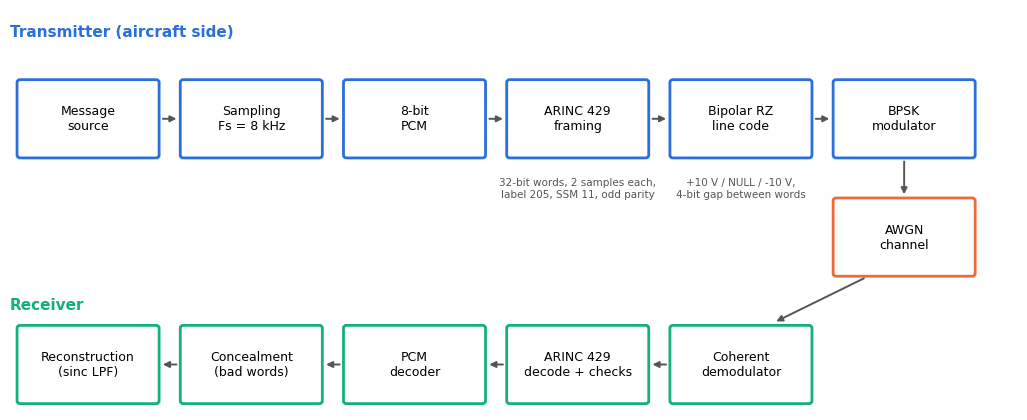

In [2]:
plots.fig_block_diagram(); plt.show()

### 3.2 Parameters

In [3]:
for k, v in vars(cfg).items():
    print(f"{k:16s} {v}")
print()
print(f"Samples: {len(txs['message'])}   ARINC words: {len(txs['words'])}   padding samples: {txs['n_pad']}")
print(f"Data bits: {txs['n_data_bits']}   simulation samples in the waveform: {n_samples}")

fs               8000.0
fm               300.0
duration         0.05
n_bits           8
label            133
sdi              0
ssm              3
gap_bits         4
samples_per_bit  40
cycles_per_bit   4
bit_rate         100000.0

Samples: 401   ARINC words: 201   padding samples: 1
Data bits: 6432   simulation samples in the waveform: 289440


### 3.3 Source and sampling

The 300 Hz sine is sampled at 8 kHz. The Nyquist rate is 600 Hz, so 8 kHz is about 13 times the minimum and there is no aliasing.

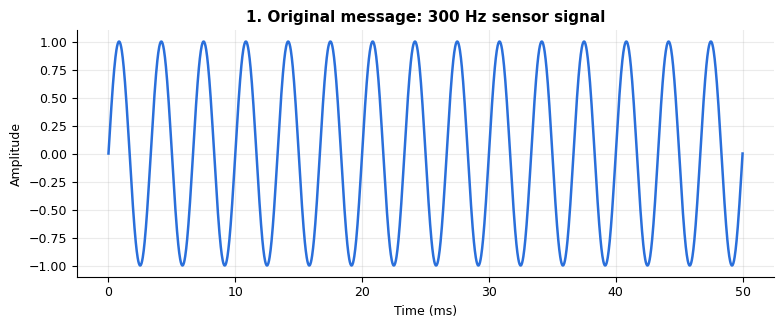

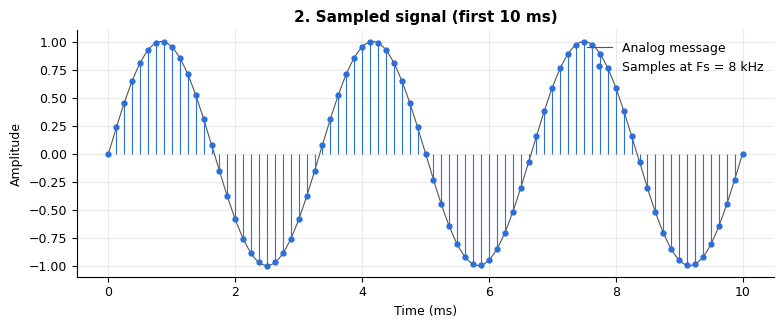

In [4]:
plots.fig_original(txs["t"], txs["message"]); plt.show()
plots.fig_sampled(txs["t"], txs["message"], cfg.fs); plt.show()

### 3.4 Quantization and PCM

An 8-bit uniform mid-rise quantizer over [−1, 1] gives 256 levels with step Δ = 2/256. The error stays within ±Δ/2. Each code is written as 8 bits, MSB first.

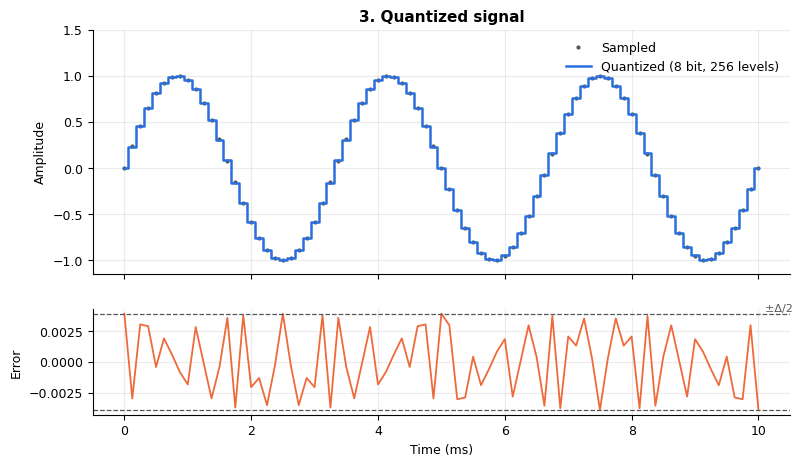

First codes: [128, 157, 186, 211, 231]
Measured quantization MSE = 6.337e-06   (step^2/12 = 5.086e-06)
SQNR = 49.0 dB   (rule 6.02n + 1.76 = 49.9 dB)


In [5]:
plots.fig_quantized(txs["t"], txs["message"], txs["quantized"], txs["step"], cfg.n_bits); plt.show()
print("First codes:", txs["codes"][:5].tolist())
print(f"Measured quantization MSE = {floor:.3e}   (step^2/12 = {txs['step']**2/12:.3e})")
print(f"SQNR = {metrics.sqnr_db(txs['message'], floor):.1f} dB   (rule 6.02n + 1.76 = {6.02*cfg.n_bits+1.76:.1f} dB)")

The measured MSE is a little above Δ²/12 because a 300 Hz tone sampled at 8 kHz repeats every 80 samples, so the error takes only 80 distinct values and is not exactly uniform.

### 3.5 ARINC 429 framing

Each 32-bit word carries two samples. The label (205 octal) is sent MSB first, as ARINC 429 requires; the rest of the word is sent LSB first. Bits 27–29 are unused and set to zero. Bit 32 is set so the word has an odd number of ones.

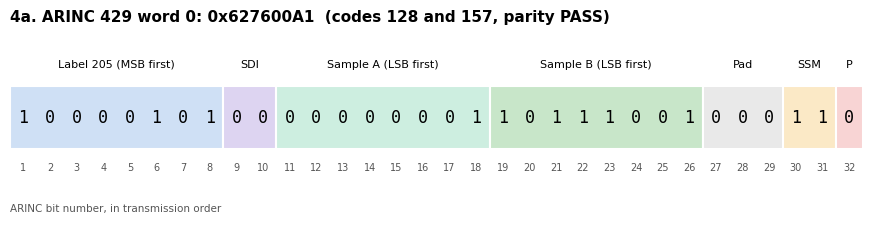

label (octal)    205
SDI              0
sample A code    128
sample B code    157
padding bits     0
SSM              11
parity bit       0
parity check     PASS


In [6]:
plots.fig_word(txs["words"][0], txs["codes"][:2]); plt.show()
for k, v in arinc429.word_field_table(txs["words"][0]).items():
    print(f"{k:16s} {v}")

### 3.6 Line coding: bipolar return-to-zero

A 1 is a +10 V pulse and a 0 is a −10 V pulse, each lasting the first half of the bit time and followed by NULL. Receivers use the 4-bit NULL gap to find the start of each word.

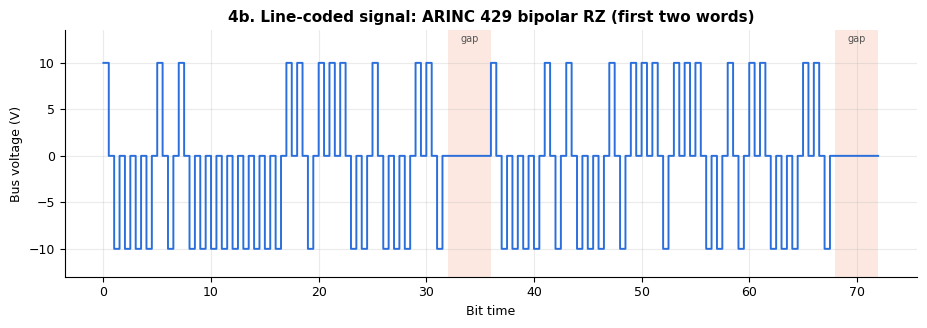

In [7]:
plots.fig_line_code(txs['baseband'], cfg.samples_per_bit, gap_bits=cfg.gap_bits); plt.show()

### 3.7 Digital modulation: BPSK

The RZ waveform multiplies a carrier with 4 cycles per bit time: $s(t) = b(t)\cos(2\pi f_c t)$, with $b(t)\in\{+1, 0, -1\}$. A 1 is a half-bit carrier burst at phase 0 and a 0 is a burst at phase π.

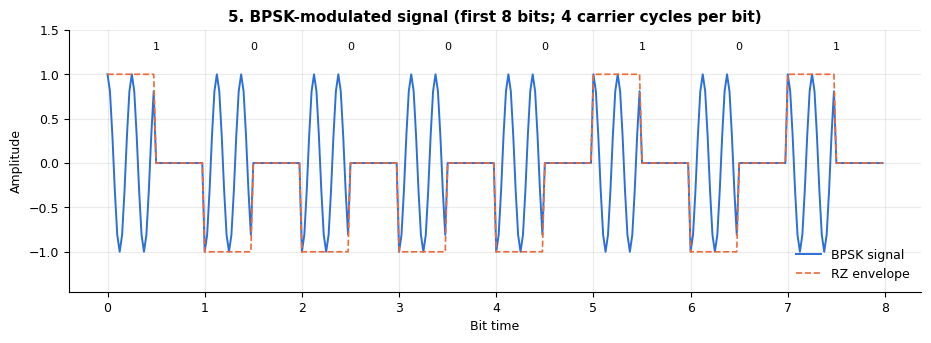

In [8]:
plots.fig_bpsk(txs['baseband'], txs['tx'], txs['words'].ravel(), cfg.samples_per_bit); plt.show()

### 3.8 AWGN channel and demodulation

Noise has variance σ² = N0/2 and is set from Eb/N0, because BER theory and the Shannon limit are both written in terms of it. The practical's template uses `awgn(x, SNR, 'measured')`, which sets the SNR per sample. For this waveform the two differ by a fixed offset:

$$\mathrm{SNR}_{\text{sample}}[\mathrm{dB}] = E_b/N_0[\mathrm{dB}] - 13.52$$

The receiver adds up 20 samples per bit, and the NULL halves and gaps add samples that carry no signal. A per-sample SNR of 0 dB is therefore already Eb/N0 ≈ 13.5 dB, which is error-free for BPSK. Sweeping only 0–25 dB of per-sample SNR would give a flat MSE curve and show nothing.

The receiver multiplies by the carrier and sums over the active half of each bit (the matched filter for the half-bit pulse), then decides on the sign.

Offset between per-sample SNR and Eb/N0: -13.52 dB


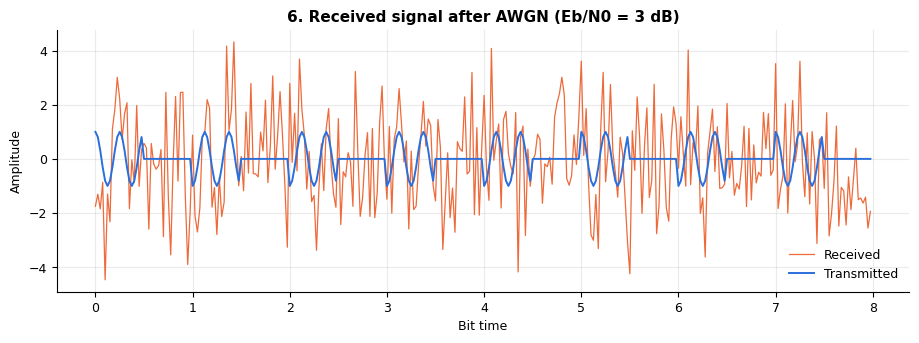

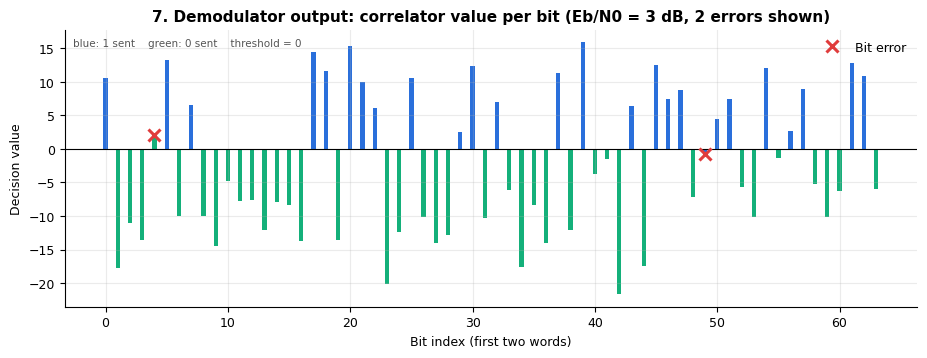

At Eb/N0 = 3 dB: 148 of 6432 bits in error (BER = 2.30e-02, theory 2.29e-02)


In [9]:
print(f"Offset between per-sample SNR and Eb/N0: {channel.snr_per_sample_db(0, txs['n_data_bits'], n_samples):.2f} dB")

r3 = system.run_link(txs, 3, np.random.default_rng(8))      # same noise draw as main.py
plots.fig_received(txs["tx"], r3["rx"], 3, cfg.samples_per_bit); plt.show()
plots.fig_demod(r3["statistics"][txs["is_data"]], txs["words"].ravel(), r3["bits"], 3); plt.show()
print(f"At Eb/N0 = 3 dB: {r3['bit_errors']} of {r3['n_bits']} bits in error "
      f"(BER = {r3['bit_errors']/r3['n_bits']:.2e}, theory {float(metrics.ber_theory(3)):.2e})")

### 3.9 Decoding and reconstruction

The receiver groups the bits back into 32-bit words and accepts a word only if parity is odd, the label is 205 and the SSM is 11. The 8-bit codes are mapped back to amplitude levels and the waveform is rebuilt with ideal low-pass (sinc) interpolation:

$$\hat m(t) = \sum_n \hat m[n]\,\mathrm{sinc}(F_s t - n)$$

Three ways of handling rejected words are compared: **raw decode** (use every word as received), **parity + hold** (repeat the last good sample) and **parity + interpolation** (interpolate linearly between the good samples on either side).

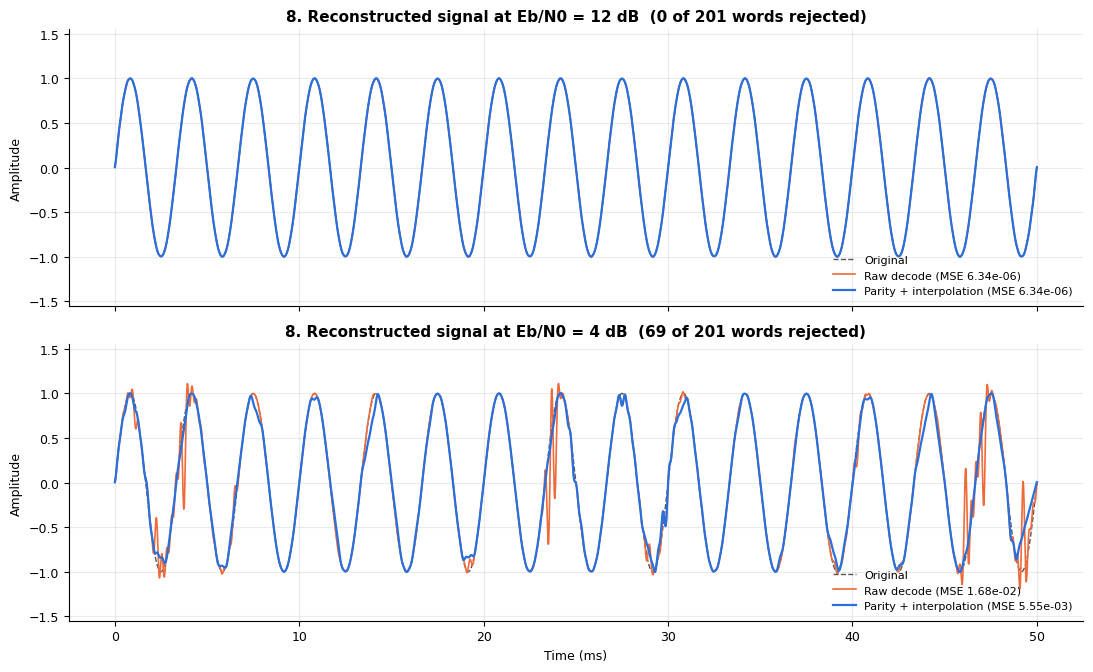

In [10]:
runs = [system.run_link(txs, e, np.random.default_rng(7)) for e in (12, 4)]
plots.fig_reconstruction(txs, runs); plt.show()

### 3.10 Parity check example

Flipping bits in a clean word (codes 231 and 246) shows what parity can and cannot catch. One flipped bit is detected. Two flipped bits leave the parity unchanged, so the wrong data is accepted.

In [11]:
word = txs["words"][2]
print(f"{'Bits flipped':<14}{'Parity':<8}Decoded codes")
for flips in ([], [15], [15, 21]):
    bad = word.copy()
    for b in flips:
        bad[b - 1] ^= 1                     # ARINC bit b is column b-1
    f = arinc429.parse_words(bad[None, :])
    note = "  (wrong, not detected)" if len(flips) == 2 else ""
    print(f"{str(flips or 'none'):<14}{'PASS' if f['parity_ok'][0] else 'FAIL':<8}"
          f"{f['codes'][0].tolist()}{note}")

Bits flipped  Parity  Decoded codes
none          PASS    [231, 246]
[15]          FAIL    [247, 246]
[15, 21]      PASS    [247, 242]  (wrong, not detected)


## 4. Performance analysis

In [12]:
TRIALS = 150            # Monte Carlo runs per Eb/N0 point (about 30 s). Use 20 for a quick look.
EBN0 = np.arange(-4, 15)
sw = system.sweep(txs, EBN0, trials=TRIALS)
sw_bb = system.sweep(txs, np.array([-4, -2, 0, 2, 4, 6, 8, 10]), trials=TRIALS, mode="baseband")
print(f"{TRIALS} runs per point, {sw['bits_per_point']:,} bits per point")

150 runs per point, 964,800 bits per point


### 4.1 Bit errors and word checks

The simulated BER follows the BPSK result $P_b = \tfrac12\,\mathrm{erfc}\sqrt{E_b/N_0}$ to within Monte Carlo scatter. The baseband ARINC bus gives the same BER at the same Eb/N0: bipolar signalling with a matched filter is antipodal, the same as BPSK, so the carrier changes the spectrum but not the error rate.

The fraction of rejected words matches the probability that a word has at least one bit error, $1-(1-P_b)^{32}$. Parity on its own misses words with an even number of errors:

$$P_{\text{undetected}} = \tfrac12\left[1+(1-2P_b)^{32}\right]-(1-P_b)^{32}$$

The simulated rate of bad words accepted is lower than this because the label and SSM checks catch some of them. At high error rates many bad words still get through.

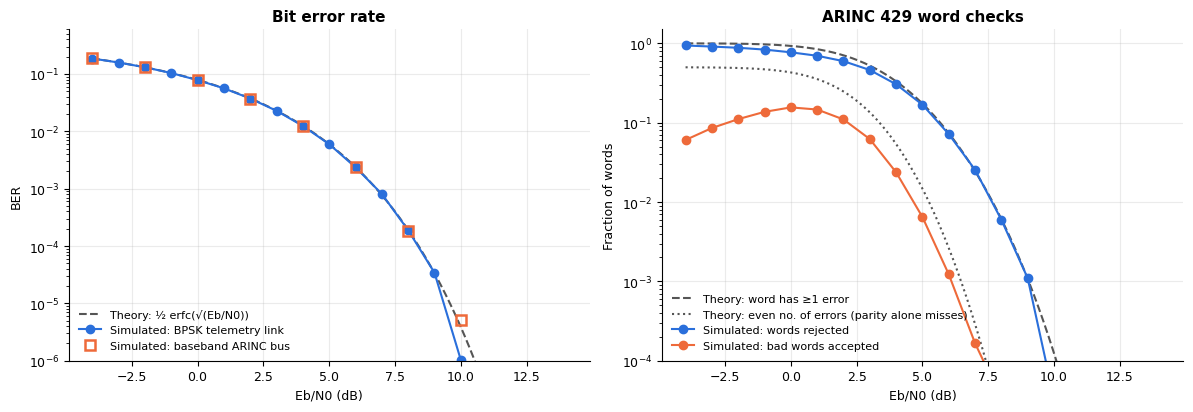

At 0 dB: 15.6% of all words are bad but accepted


In [13]:
plots.fig_ber_words(sw, sw_bb); plt.show()
i0 = int(np.flatnonzero(sw["ebn0_db"] == 0)[0])
print(f"At 0 dB: {100*sw['undetected_rate'][i0]:.1f}% of all words are bad but accepted")

### 4.2 Reconstruction MSE against channel SNR

An error in bit *k* of an *n*-bit code shifts the sample by $2^k\Delta$. With independent errors at rate $P_b$ the expected squared error per sample is

$$\sum_{k=0}^{n-1} P_b\,(2^k\Delta)^2 = P_b\,\Delta^2\,\frac{4^n-1}{3}\approx \tfrac43 P_b \quad(\Delta = 2/2^n)$$

so $\mathrm{MSE}_{\text{raw}}\approx \mathrm{MSE}_q + \tfrac43 P_b$. Errors in the most significant bit dominate.

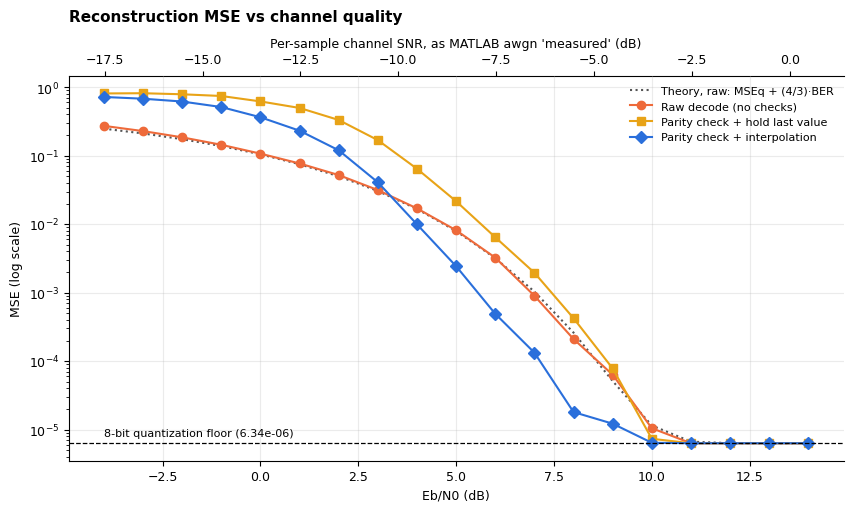

In [14]:
plots.fig_mse(sw, floor, txs['n_data_bits'], n_samples); plt.show()

In [15]:
print(f"{'Eb/N0':>6} {'SNR/sample':>11} {'BER':>10} {'BER theory':>11} {'MSE raw':>10} {'MSE hold':>10} {'MSE interp':>11}")
for e in (0, 2, 4, 6, 8, 10, 12):
    i = int(np.flatnonzero(sw["ebn0_db"] == e)[0])
    print(f"{e:6d} {channel.snr_per_sample_db(e, txs['n_data_bits'], n_samples):11.1f} "
          f"{sw['ber'][i]:10.2e} {float(metrics.ber_theory(e)):11.2e} "
          f"{sw['mse_raw'][i]:10.2e} {sw['mse_hold'][i]:10.2e} {sw['mse_interp'][i]:11.2e}")

from scipy.optimize import brentq
knee = brentq(lambda e: metrics.mse_raw_theory(e, floor) - 2 * floor, 5, 14)
print(f"\nChannel contribution equals the quantization floor at Eb/N0 = {knee:.1f} dB")

 Eb/N0  SNR/sample        BER  BER theory    MSE raw   MSE hold  MSE interp
     0       -13.5   7.81e-02    7.86e-02   1.07e-01   6.20e-01    3.64e-01
     2       -11.5   3.73e-02    3.75e-02   5.21e-02   3.32e-01    1.20e-01
     4        -9.5   1.24e-02    1.25e-02   1.70e-02   6.44e-02    9.94e-03
     6        -7.5   2.35e-03    2.39e-03   3.25e-03   6.44e-03    4.91e-04
     8        -5.5   1.89e-04    1.91e-04   2.10e-04   4.24e-04    1.81e-05
    10        -3.5   1.04e-06    3.87e-06   1.05e-05   7.35e-06    6.43e-06
    12        -1.5   0.00e+00    9.01e-09   6.34e-06   6.34e-06    6.34e-06



Channel contribution equals the quantization floor at Eb/N0 = 9.9 dB


**Effect of channel SNR.** Above about 10 dB Eb/N0 (−3.6 dB per-sample SNR) bit errors are rare and the MSE stays at the 8-bit quantization floor. More SNR does not improve it. Below that point the MSE rises quickly.

**Effect of the parity check.** Parity only helps if the receiver has something better to put in place of a rejected word.

- **Holding the last good value is worse than doing nothing over most of the range.** Most rejected words are wrong only in a low-order bit, which costs little. Holding throws away two good samples of a sine that can change by up to 0.24 per sample.
- **Interpolation does better from about 4 dB upward.** It reduces the MSE about 7 times at 6 dB and 12 times at 8 dB. Below about 3 dB most words are rejected, the gaps become long, and interpolation does worse than the raw decoder.

With detection-only checks, as in ARINC 429, the choice of concealment method makes as much difference as a few dB of SNR.

## 5. Discussion: link to Shannon's channel capacity theorem

Shannon's theorem gives the highest rate a band-limited AWGN channel can carry with arbitrarily small error probability:

$$C = B\log_2\!\left(1+\frac{S}{N}\right),\qquad \frac SN = \frac{E_b}{N_0}\frac{R_b}{B}$$

Setting $C=R_b$ gives the smallest Eb/N0 at which the bit rate can be carried at all:

$$\left(\frac{E_b}{N_0}\right)_{\min} = \frac{2^{R_b/B}-1}{R_b/B}$$

With half-bit pulses the BPSK signal occupies about $B = 4R_b$ between spectral nulls, which gives −1.21 dB. As $B\to\infty$ this falls to $\ln 2 = -1.59$ dB, the Shannon limit.

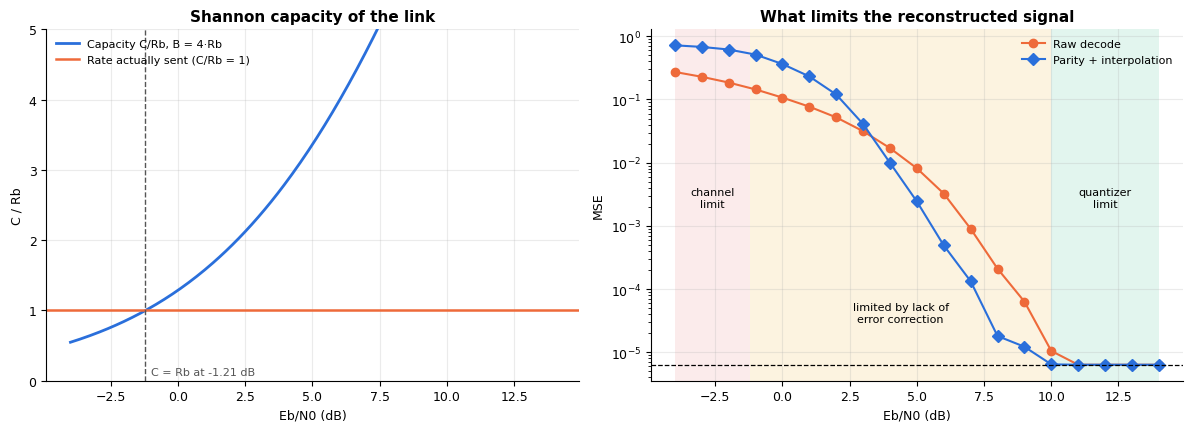

Minimum Eb/N0 for C = Rb with B = 4 Rb : -1.21 dB
Limit as B -> infinity (ln 2)           : -1.59 dB


In [16]:
plots.fig_shannon(sw, floor); plt.show()
print(f"Minimum Eb/N0 for C = Rb with B = 4 Rb : {metrics.shannon_min_ebn0_db(0.25):.2f} dB")
print(f"Limit as B -> infinity (ln 2)           : {10*np.log10(np.log(2)):.2f} dB")

The MSE curve splits into three regions:

1. **Below −1.2 dB: the channel is the bottleneck.** Capacity is less than the bit rate, so no modulation or coding scheme can deliver the samples without errors. The only options are a lower bit rate (fewer bits per sample or a lower Fs) or more transmit power.
2. **From −1.2 dB to about 10 dB: the design is the bottleneck.** The channel could carry the data without errors, but uncoded BPSK needs about 10 dB before bit errors become smaller than quantization error. ARINC 429 has only parity, which detects some errors and corrects none. An error-correcting code could move the knee most of the way toward the Shannon limit. Modern codes come within about 1–2 dB of it.
3. **Above about 10 dB: the quantizer is the bottleneck.** The error is set by the 8-bit quantizer. Each extra bit per sample would lower the MSE floor by about 6 dB, at the cost of 12.5% more bits on the link.

In [17]:
word_bits, gap = 32, cfg.gap_bits
useful = 2 * cfg.n_bits
print(f"Framing overhead: {useful} of every {word_bits + gap} bit times carry sample bits ({100*useful/(word_bits+gap):.0f}%)")
words_per_s = cfg.bit_rate / (word_bits + gap)
print(f"100 kbit/s bus: {words_per_s:.0f} words/s = {2*words_per_s:.0f} samples/s")
print(f"Fs = 8 kHz at 8 bits per sample in this framing needs {cfg.fs/2*(word_bits+gap)/1e3:.0f} kbit/s")

Framing overhead: 16 of every 36 bit times carry sample bits (44%)
100 kbit/s bus: 2778 words/s = 5556 samples/s
Fs = 8 kHz at 8 bits per sample in this framing needs 144 kbit/s


**Framing overhead.** The label, SDI, SSM, parity and gap make each word self-identifying on a shared bus, but in Shannon's terms they are overhead. The gap carries no energy, so measured per sample bit the energy needed doubles (3 dB). This system needs about 13 dB per information bit, against the −1.59 dB limit.

**The bus rate as a bottleneck.** A high-speed ARINC 429 bus can send at most about 2778 words per second, which is 5556 samples per second with two samples per word. Sending Fs = 8 kHz at 8 bits per sample in this framing needs 144 kbit/s, so a real ARINC 429 bus could not carry this stream in real time. Here the protocol's data rate runs out before noise becomes a problem. A 300 Hz signal only needs Fs of about 12 kHz, which fits easily.

## 6. Conclusions

- The full chain works end to end. With a good channel the signal is recovered to within 8-bit quantization error (MSE 6.34 × 10⁻⁶, SQNR 49.0 dB).
- The BER of both the BPSK link and the baseband ARINC bus matches theory. The carrier does not change the error rate at a given Eb/N0.
- Reconstruction quality is set by channel errors below about 10 dB Eb/N0 and by the quantizer above it, following MSE_q + (4/3)·P_b.
- Parity lets the receiver drop bad words, but whether that helps depends on what replaces them. Holding the last value made the result worse; interpolation made it better.
- Shannon's theorem allows this rate to be carried error-free from −1.21 dB. The 11 dB gap to the knee is what error-correcting coding could recover. ARINC 429 has none.

## 7. Limitations

- Bit, word and carrier timing are assumed known at the receiver. A real ARINC 429 receiver recovers timing from the RZ transitions and finds word boundaries from the NULL gap.
- The channel adds only white Gaussian noise. There is no interference, cable dispersion, fading or impulse noise.
- Label 205 and the two-samples-per-word packing were chosen for this lab. A real system uses the label assignments and data formats (BNR or BCD) from the equipment specification.